# Прогнозирование следующей покупки

# Введение

**Описание**

Интернет-магазин собирает историю покупателей, проводит рассылки предложений и планирует будущие продажи. Для оптимизации процессов надо выделить пользователей, которые готовы совершить покупку в ближайшее время.

**Цель проекта**

Построить модель, которая предсказывает пользователей, готовых совершить покупку в ближайшее время.

**Описание данных**

*apparel-purchases.csv* - данные о покупках клиентов по дням и по товарам. В каждой записи покупка определенного товара, его цена, количество штук:

* client_id - идентификатор клиента
* quantity - количество единиц товара
* price - цена товара
* category_ids - идентификаторы категорий
* date (date_purchases) - дата покупки
* message_id - идентификатор сообщения из рассылки

*apparel-messages.csv* - рассылки, которые были отправлены клиентам из таблицы покупок:

* bulk_campaign_id - идентификатор рассылки
* client_id - идентификатор клиента
* message_id - идентификатор сообщения
* event - действие с сообщением (отправлено, открыто, покупка…)
* channel - канал рассылки
* date (date_message) - дата действия
* created_at (date_message_fully) - дата-время полностью

*target.csv* - данные с идентификатором клиента и факта покупки в целевой период:

* client_id - идентификатор клиента
* target - клиент совершил покупку в целевом периоде

# Импорт библиотек

In [ ]:
# Работа с данными
import pandas as pd
import numpy as np
pd.set_option('display.max_columns', None)

# Машинное обучение и валидация
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, precision_score, confusion_matrix, recall_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

# Интерпретация моделей
import shap

# Визуализация и отображение
import matplotlib.pyplot as plt
import seaborn as sns

# Константы
RANDOM_STATE = 42


Загружаем датасеты:

In [ ]:
df_messages = pd.read_csv('/content/apparel-messages.csv')
df_purchases = pd.read_csv('/content/apparel-purchases.csv')
df_target = pd.read_csv('/content/apparel-target_binary.csv')

# df_messages

## Первичный обзор данных

Выполним первичный обзор данных:

In [ ]:
df_messages.head()

,bulk_campaign_id,client_id,message_id,event,channel,date,created_at
0,4439,1515915625626736623,1515915625626736623-4439-6283415ac07ea,open,email,2022-05-19,2022-05-19 00:14:20
1,4439,1515915625490086521,1515915625490086521-4439-62834150016dd,open,email,2022-05-19,2022-05-19 00:39:34
2,4439,1515915625553578558,1515915625553578558-4439-6283415b36b4f,open,email,2022-05-19,2022-05-19 00:51:49
3,4439,1515915625553578558,1515915625553578558-4439-6283415b36b4f,click,email,2022-05-19,2022-05-19 00:52:20
4,4439,1515915625471518311,1515915625471518311-4439-628341570c133,open,email,2022-05-19,2022-05-19 00:56:52


In [ ]:
df_messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2895632 entries, 0 to 2895631
Data columns (total 7 columns):
 #   Column            Dtype 
---  ------            ----- 
 0   bulk_campaign_id  int64 
 1   client_id         int64 
 2   message_id        object
 3   event             object
 4   channel           object
 5   date              object
 6   created_at        object
dtypes: int64(2), object(5)
memory usage: 154.6+ MB


Промежуточный вывод:

- вероятно, столбцы date и created_at дублируют друг друга
- столбец date и created_at имеют формат данных object

Проверим данные на наличие пропусков:

In [ ]:
df_messages.isna().any().any()

np.True_

Пропуски отсутсвуют

Проверим данные на наличие полных дубликатов:

In [ ]:
# Считаем дубликаты и сохраняем в переменную
dup_count = df_messages.duplicated().sum()

# Выводим результаты
print(f'Количество дублирующихся строк: {dup_count} шт.')
print(f'Доля дублирующихся строк: {round((dup_count * 100) / df_messages.shape[0], 2)} %')

Количество дублирующихся строк: 1335 шт.
Доля дублирующихся строк: 0.05 %


Дублирующиеся строки могут быть результатом ошибки выгрузки данных. Если передать такие данные модели, это приведет к утечке данных и переобучению модели.

Избавимся от дубликатов:

In [ ]:
df_messages.drop_duplicates(inplace=True)

dup_count = df_messages.duplicated().sum()

print(f'Количество дублирующихся строк: {dup_count} шт.')

Количество дублирующихся строк: 0 шт.


Проверим, дублируют ли столбцы date и created_at друг друга:

In [ ]:
# Переформатируем столбцы с датами в формат дат
df_messages['date'] = pd.to_datetime(df_messages['date'])
df_messages['created_at'] = pd.to_datetime(df_messages['created_at'])

# Сверяем даты двух столбцов
if (df_messages['created_at'].dt.date == df_messages['date'].dt.date).any():
    print('Даты в столбцах полностью совпадают')
else:
    print('Обнаружены расхождения в датах')

Даты в столбцах полностью совпадают


Так как даты в столбцах полностью совпадают, оставим самый информативный признак - `created_at`:

In [ ]:
print('Количество признаков до удаления created_at:', df_messages.shape[1])
df_messages.drop(columns=['date'], inplace=True)
print('Количество признаков после удаления created_at:', df_messages.shape[1])

Количество признаков до удаления created_at: 7
Количество признаков после удаления created_at: 6


## Исследовательский анализ данных

### Анализ распределения признаков

Изучим признак `event`:

In [ ]:
counts_event = df_messages['event'].value_counts(normalize=True).mul(100).round(2)

counts_event.index.name = 'Категории'
counts_event = counts_event.rename('Процент, %')

counts_event

,"Процент, %"
Категории,
send,70.79
open,21.40
click,6.53
purchase,1.03
hard_bounce,0.16
soft_bounce,0.06
unsubscribe,0.03
hbq_spam,0.01
subscribe,0.00


Категории признака `event` распределены неравномерно. Объединим редкие категории признака `event` в общую категорию `other`. Это операция хороша по следующим причинам:
- Борьба с избыточной разреженностью
- Снижение риска переобучения
- Экономия памяти и ускорение обучения

Категорию purchase (0.99 %) имеет смысл оставить отдельным событием, так как это ключевое целевое действие

In [ ]:
# Объединяем редкие категории в общую категорию
rare_cat = ['hard_bounce', 'soft_bounce', 'unsubscribe', 'hbq_spam', 'subscribe', 'complain', 'close']

df_messages['event_grouped'] = df_messages['event'].replace(rare_cat, 'other')

major_and_other = df_messages['event_grouped'].value_counts(normalize=True).mul(100).round(2)

major_and_other.index.name = 'Категории'
major_and_other = major_and_other.rename('Процент, %')

major_and_other

,"Процент, %"
Категории,
send,70.79
open,21.40
click,6.53
purchase,1.03
other,0.25


Отобразим распределение графически:

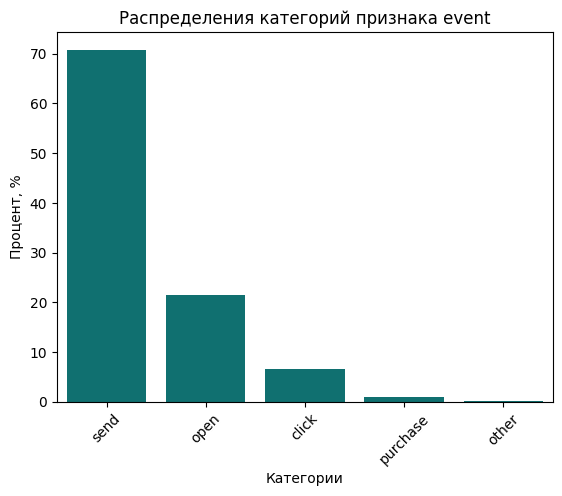

In [ ]:
sns.barplot(major_and_other, color='teal')

plt.xticks(rotation=45)
plt.title('Распределения категорий признака event');

Данные события согласуются с воронкой конверсии: сначала клиенту отпраляют рассылку `send`, затем они открывают её `open`, кликают `click` на ссылку и совершают покупку `purchases`



Изучим категории признака `channel`:

In [ ]:
counts_channel = df_messages['channel'].value_counts(normalize=True).mul(100).round(2)

counts_channel.index.name = 'Категории'
counts_channel = counts_channel.rename('Процент, %')

counts_channel

,"Процент, %"
Категории,
email,64.18
mobile_push,35.82


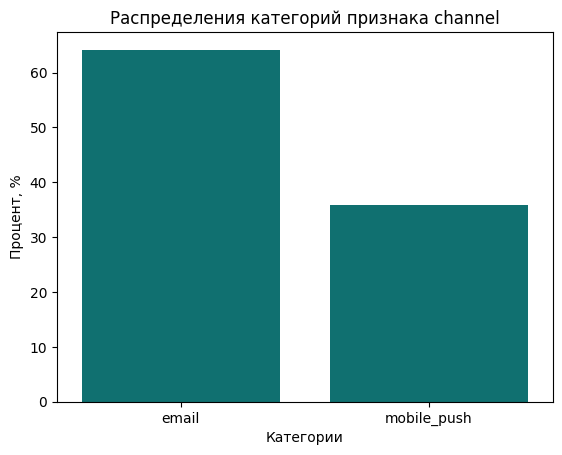

In [ ]:
sns.barplot(counts_channel, color='teal')

plt.title('Распределения категорий признака channel');

Рекламные уведомления поступают двумя способами: черeз `email` (основной способ) и мобильные уведомления `mobile_push`

### Анализ временных рядов

Выведем период маркетинговых наблюдений (в каком диапазоне дат представлен датасет):

In [ ]:
last_date = df_messages['created_at'].max().date()
min_date = df_messages['created_at'].min().date()

market_period_day = (last_date - min_date).days

print(f'Маркетинговая кампания проводилась с {min_date} по {last_date} в течение {market_period_day} дней')

Маркетинговая кампания проводилась с 2022-05-19 по 2022-12-05 в течение 200 дней


Исследуем динамику активности маркетинга и пользователей по месяцам:

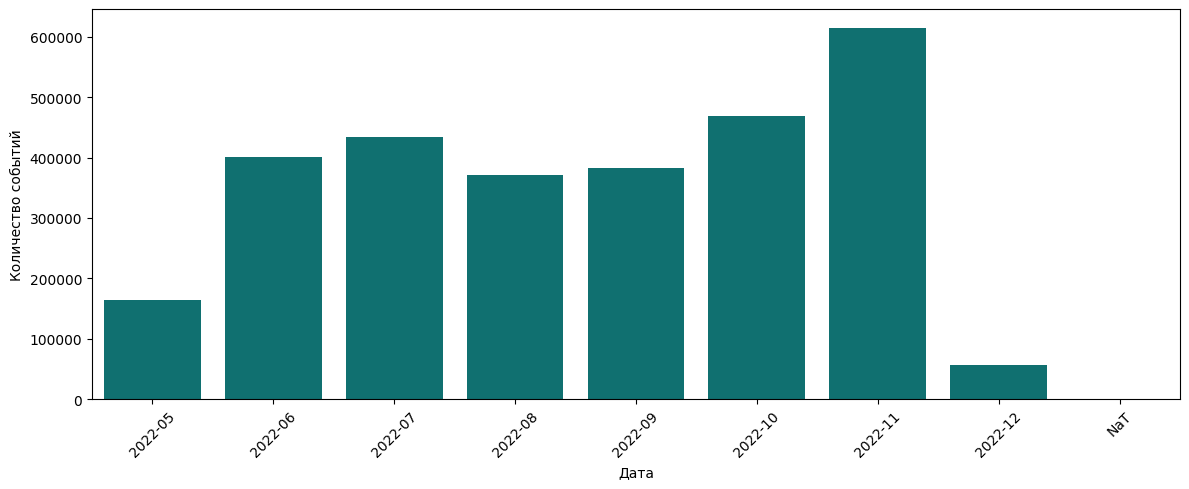

In [ ]:
# Преобразуем дату в "год_месяц"
df_messages['year_month'] = df_messages['created_at'].dt.to_period('M').astype('str')

# Считаем число событий "год_месяц"
year_month_count = df_messages['year_month'].value_counts().sort_index().reset_index()

# Переименовываем признаки
year_month_count.columns = ['Дата', 'Количество событий']

# Строим график
plt.figure(figsize=(12, 5))
sns.barplot(
    data=year_month_count,
    x='Дата',
    y='Количество событий',
    color='teal'
    )

plt.xticks(rotation=45)
plt.tight_layout();

Анализируя данный график, можно сделать следующие выводы:
-  Общий растущий тренд: бизнес развивается. Если в середине 2022 года количество событий колеблется в районе 400 тыс., то в 2023 году в этом же месяце число событий около 600 тыс.
- Выраженная сезонность: выраженная активность в конце года, сниженная активность в начале года

Исследуем динамику отправленных, открытых и кликнутый сообщений по месяцам:

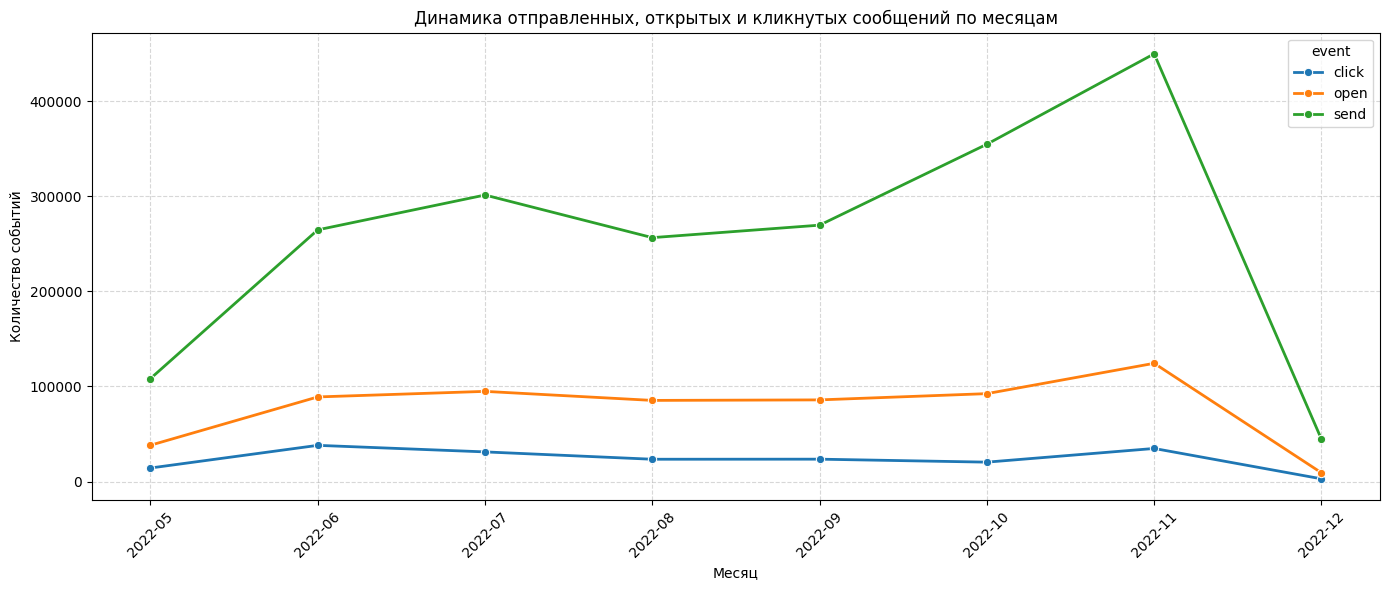

In [ ]:
# Выделим только ключевые события для анализа динамики
key_events = ['send', 'open', 'click']
df_key_events = df_messages[df_messages['event'].isin(key_events)]

# Группируем по месяцам и типам событий
trend_data = (
    df_key_events
    .groupby(['year_month', 'event'])
    .size()
    .reset_index(name='count')
)

# Строим график динамики
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=trend_data,
    x='year_month',
    y='count',
    hue='event',
    marker='o',
    linewidth=2
)

plt.title('Динамика отправленных, открытых и кликнутых сообщений по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество событий')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Выводы:
- Низкая визуальная чувствительность кликов: даже при резких скачках отправок линия кликов колеблется незначительно
- кривая открытий практически полностью повторяет изгибы линии отправок. Это означает, что процент открытий удерживается на относительно постоянном уровне независимо от масштаба рассылок

Исследуем активность пользователей по дням и по часам:

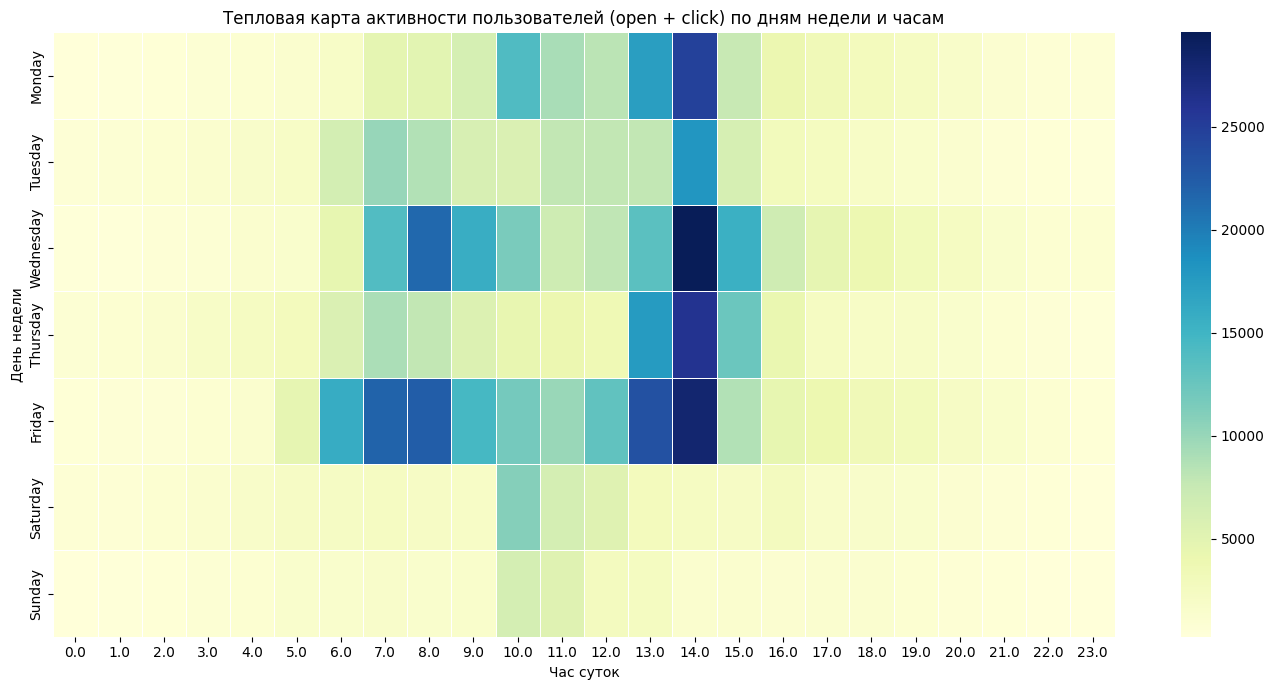

In [ ]:
# Извлекаем день недели и час
df_messages['day_of_week'] = df_messages['created_at'].dt.day_name()
df_messages['hour'] = df_messages['created_at'].dt.hour

# Фильтруем данные только для открытий и кликов
client_activity = df_messages[df_messages['event'].isin(['open', 'click'])].copy()

# Порядок дней недели для графика
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
client_activity['day_of_week'] = pd.Categorical(client_activity['day_of_week'], categories=days_order, ordered=True)

# Группируем данные для построения тепловой карты
heatmap_data = client_activity.pivot_table(
    index='day_of_week',
    columns='hour',
    values='event',
    aggfunc='count',
    fill_value=0,
    observed=False
)

# Визуализация тепловой карты активности
plt.figure(figsize=(14, 7))
sns.heatmap(
    heatmap_data,
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Тепловая карта активности пользователей (open + click) по дням недели и часам')
plt.xlabel('Час суток')
plt.ylabel('День недели')
plt.tight_layout()
plt.show()

Выводы:
- Четкий рабочий график активности: концентрация в будние дни и спад в выходные дни
- Внутридневные интервалы и пиковые часы: активность клиентов концентрируется в интервале с 07:00 до 16:00 с резким затуханием после 17:00. Абсолютный максимум активности приходится на 14:00
- Поведение аудитории напоминает офисных работников, проверяющих почту в рабочее время за компьютером. Пик в 14:00 совпадает со временем после обеденного перерыва, когда пользователи возвращаются к рабочим местам и разбирают входящие сообщения.

### Маркетинговая воронка конверсии

Маркетинговая воронка конверсии  описывает путь клиента от самого первого знакомства с продуктом до совершения целевого действия (покупки, регистрации, подписки).

Исследуем конверсию этапов воронки относительно первого этапа - `send`:

In [ ]:
# Этапы воронки
funnel_stages  = ['send', 'open', 'click', 'purchase']

# Данные с этапами funnel_stages
convertion_data = df_messages[df_messages['event'].isin(funnel_stages)]

# Группировка данных по этапам воронки
funnel_data = convertion_data.groupby(['event']).size().reset_index(name='count')

# Выстраивание последовательности 'send', 'open', 'click', 'purchase'
funnel_data['event'] = pd.Categorical(
    funnel_data['event'],
    categories=funnel_stages,
    ordered=True
    )

funnel_data = funnel_data.sort_values('event')

# Получения числа, относительно которого считается конверсия
send_count = funnel_data[funnel_data['event'] == 'send']['count'].iloc[0]

# Рассчёт конверсии
funnel_data['conversion_%'] = (
    funnel_data['count'] / send_count * 100
).round(2)

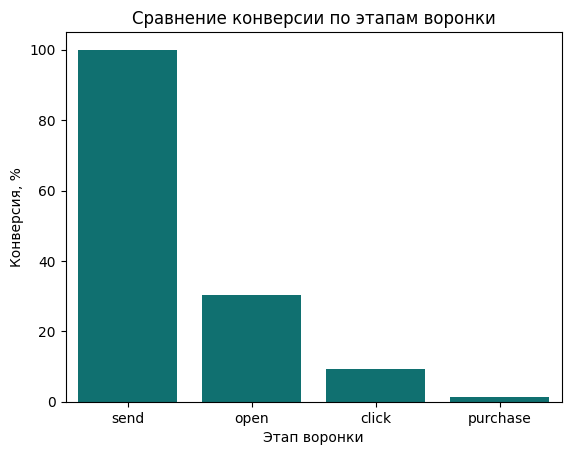

In [ ]:
sns.barplot(
    data=funnel_data,
    x='event',
    y='conversion_%',
    color='teal'
    )

plt.xlabel('Этап воронки')
plt.ylabel('Конверсия, %')
plt.title('Сравнение конверсии по этапам воронки');

In [ ]:
# Выводим таблицу
funnel_data.rename(columns={
    'event': 'Этап воронки',
    'count': 'Число событий',
    'conversion_%': 'Конверсия, %'
})

,Этап воронки,Число событий,"Конверсия, %"
3,send,2048963,100.00
1,open,619383,30.23
0,click,188942,9.22
2,purchase,29683,1.45


Вывода:
- Каждое третье отправленное сообщение (33.70%) открывается пользователями
- Основная потеря потенциальных клиентов происходит на этапе перехода от открытия `open` к клику `click`
- До итоговой покупки доходит 0.69% от изначально отправленного объема сообщений.

Сравним этапы воронки в разрезе email и mobile_push:

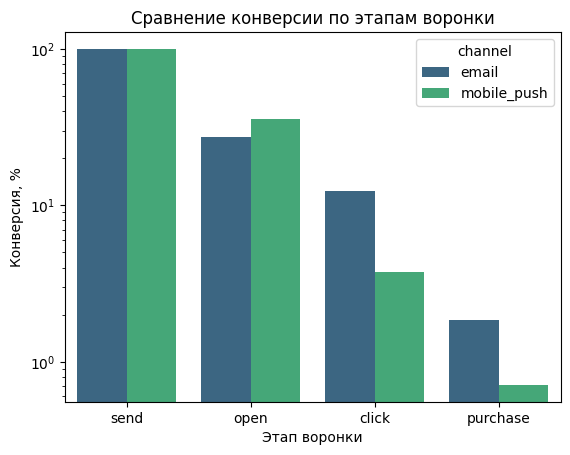

In [ ]:
# Группировка данных по этапам воронки
funnel_data_channel = convertion_data.groupby(['event', 'channel']).size().reset_index(name='count')

# Выстраивание последовательности 'send', 'open', 'click', 'purchase'
funnel_data_channel['event'] = pd.Categorical(
    funnel_data_channel['event'],
    categories=funnel_stages,
    ordered=True
    )

funnel_data_channel = funnel_data_channel.sort_values('event')

# Считаем конверсию относительно первого события - send
send_base = funnel_data_channel[funnel_data_channel['event'] == 'send'].set_index('channel')['count']
funnel_data_channel['conversion_%'] = (funnel_data_channel['count'] / funnel_data_channel['channel'].map(send_base) * 100).round(2)

# Строим график
sns.barplot(
    data=funnel_data_channel,
    x='event',
    y='conversion_%',
    hue='channel',
    palette='viridis'
    )
plt.xlabel('Этап воронки')
plt.ylabel('Конверсия, %')
plt.title('Сравнение конверсии по этапам воронки')
plt.yscale('log')
plt.show()

In [ ]:
# Выводим таблицу
funnel_data_channel.rename(columns={
    'event': 'Этап воронки',
    'channel': 'Канал',
    'count': 'Число событий',
    'conversion_%': 'Конверсия, %'
})

,Этап воронки,Канал,Число событий,"Конверсия, %"
6,send,email,1311208,100.00
7,send,mobile_push,737755,100.00
2,open,email,357866,27.29
3,open,mobile_push,261517,35.45
0,click,email,161148,12.29
1,click,mobile_push,27794,3.77
4,purchase,email,24425,1.86
5,purchase,mobile_push,5258,0.71


Выводы:
- Пуши доставляются на экран смартфона и открываются почти в 2 раза чаще.
- Несмотря на более высокий показатель открываемости у Mobile Push, их конверсия в клики существенно уступает показателям Email-рассылок
- Email в 3 раза эффективнее конвертирует сообщения в продажи, чем мобильные пуши.

## Группировка данных

Сгруппируем данные по client_id:

In [ ]:
# Считаем количество событий каждого типа раздельно по каналам (email и mobile_push)
channel_events = pd.crosstab(
    df_messages['client_id'],
    [df_messages['channel'], df_messages['event']]
).reset_index()

# Схлопываем мультииндекс колонок в плоский вид
new_columns = []
for col in channel_events.columns:
  if col[0] == 'client_id':
    new_columns.append('client_id')
  else:
    new_columns.append(f'{col[0]}_{col[1]}')
channel_events.columns = new_columns

# Email-метрики
channel_events['email_open_rate'] = (channel_events['email_open'] / channel_events['email_send'].replace(0, 1)).round(4)
channel_events['email_ctor'] = (channel_events['email_click'] / channel_events['email_open'].replace(0, 1)).round(4)

# Push-метрики
channel_events['push_open_rate'] = (channel_events['mobile_push_open'] / channel_events['mobile_push_send'].replace(0, 1)).round(4)
channel_events['push_ctor'] = (channel_events['mobile_push_click'] / channel_events['mobile_push_open'].replace(0, 1)).round(4)

# Негативные сигналы (отписки, жалобы на спам, bounce-ошибки)
channel_events['negative_signals'] = (
    channel_events['email_unsubscribe'] +
    channel_events['email_hbq_spam'] +
    channel_events['email_hard_bounce'] +
    channel_events['email_soft_bounce'] +
    channel_events['mobile_push_hard_bounce']
)

# Рассчитаем давность последней активности (в днях)
global_max_msg_date = df_messages['created_at'].max()
last_msg = df_messages.groupby('client_id')['created_at'].max().reset_index(name='last_msg_date')
last_msg['days_since_last_message'] = (global_max_msg_date - last_msg['last_msg_date']).dt.days

# Объединяем все полученные метрики
client_messages = channel_events.merge(
    last_msg[['client_id', 'days_since_last_message']],
    on='client_id',
    how='left'
)

# Итоговый список колонок для агрегированной таблицы
columns_to_keep = [
    'client_id',
    'email_send', 'email_open', 'email_click',
    'email_open_rate', 'email_ctor',
    'mobile_push_send', 'mobile_push_open', 'mobile_push_click',
    'push_open_rate', 'push_ctor',
    'negative_signals',
    'days_since_last_message'
]

# Агрегированная таблицы
client_messages_final = client_messages[columns_to_keep]

display(client_messages_final.head())

,client_id,email_send,email_open,email_click,email_open_rate,email_ctor,mobile_push_send,mobile_push_open,mobile_push_click,push_open_rate,push_ctor,negative_signals,days_since_last_message
0,1515915625468060902,43,17,8,0.3953,0.4706,0,0,0,0.0,0.0,0,5
1,1515915625468061003,49,1,0,0.0204,0.0000,0,0,0,0.0,0.0,0,0
2,1515915625468061099,52,9,4,0.1731,0.4444,44,22,0,0.5,0.0,1,0
3,1515915625468061100,0,0,0,0.0000,0.0000,68,0,0,0.0,0.0,0,0
4,1515915625468061170,38,12,9,0.3158,0.7500,0,0,0,0.0,0.0,0,0


# df_purchases

## Первичный обзор данных

In [ ]:
df_purchases.head()

,client_id,quantity,price,category_ids,date,message_id
0,1515915625468169594,1,1999.0,"['4', '28', '57', '431']",2022-05-16,1515915625468169594-4301-627b661e9736d
1,1515915625468169594,1,2499.0,"['4', '28', '57', '431']",2022-05-16,1515915625468169594-4301-627b661e9736d
2,1515915625471138230,1,6499.0,"['4', '28', '57', '431']",2022-05-16,1515915625471138230-4437-6282242f27843
3,1515915625471138230,1,4999.0,"['4', '28', '244', '432']",2022-05-16,1515915625471138230-4437-6282242f27843
4,1515915625471138230,1,4999.0,"['4', '28', '49', '413']",2022-05-16,1515915625471138230-4437-6282242f27843


In [ ]:
df_purchases.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202208 entries, 0 to 202207
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   client_id     202208 non-null  int64  
 1   quantity      202208 non-null  int64  
 2   price         202208 non-null  float64
 3   category_ids  202208 non-null  object 
 4   date          202208 non-null  object 
 5   message_id    202208 non-null  object 
dtypes: float64(1), int64(2), object(3)
memory usage: 9.3+ MB


Промежуточный вывод:
- В данных нет явных пропусков
- Признак `date` имеет тип данных `object`

Для дальнейшего удобства работы изменим тип данных признака `date`:

In [ ]:
df_purchases['date'] = pd.to_datetime(df_purchases['date'])

df_purchases['date'].dtypes

dtype('<M8[ns]')

Проверим данные на наличие явных дубликатов:

In [ ]:
# Считаем дубликаты и сохраняем в переменную
dup_count = df_purchases.duplicated().sum()

# Выводим результаты
print(f'Количество дублирующихся строк: {dup_count} шт.')
print(f'Доля дублирующихся строк: {round((dup_count * 100) / df_messages.shape[0], 2)} %')

Количество дублирующихся строк: 73020 шт.
Доля дублирующихся строк: 2.52 %


Дублирующиеся строки могут быть результатом ошибки выгрузки данных. Если передать такие данные модели, это приведет к утечке данных и переобучению модели.

Избавимся от дубликатов:

In [ ]:
df_purchases.drop_duplicates(inplace=True)

dup_count = df_purchases.duplicated().sum()

print(f'Количество дублирующихся строк: {dup_count} шт.')

Количество дублирующихся строк: 0 шт.


## Исследовательский анализ данных

### Анализ распределения цен и количества товаров в покупке

In [ ]:
df_purchases[['quantity', 'price']].describe()

,quantity,price
count,129188.000000,129188.000000
mean,1.009420,1264.532766
std,0.220332,1375.016339
min,1.000000,1.000000
25%,1.000000,399.000000
50%,1.000000,999.000000
75%,1.000000,1750.000000
max,30.000000,85499.000000


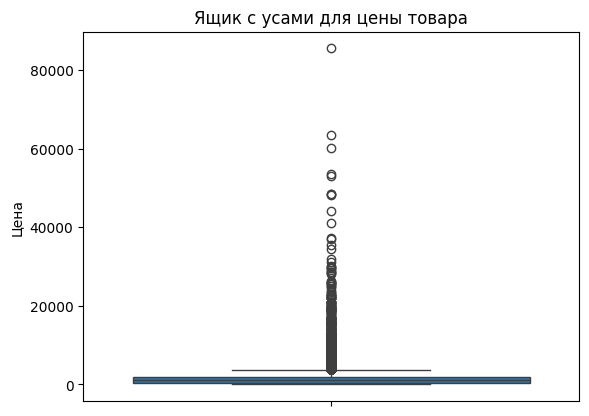

In [ ]:
sns.boxplot(df_purchases['price'])
plt.ylabel('Цена')
plt.title('Ящик с усами для цены товара');

Выводы:
- В данных о ценах товаров наблюдаются значительные выбросы: при медиане около 987 руб. максимальное значение достигает 85 499 руб
- Среди товаров есть те, которые стоят 1 рубль. Это товары купленный за счёт бонусов
- Количество купленных товаров не превышает 30 штук. Чаще всего клиенты покупают 1 единицу товара

Построим распределение цен товаров с исключением выбросов для лучшей визуализации

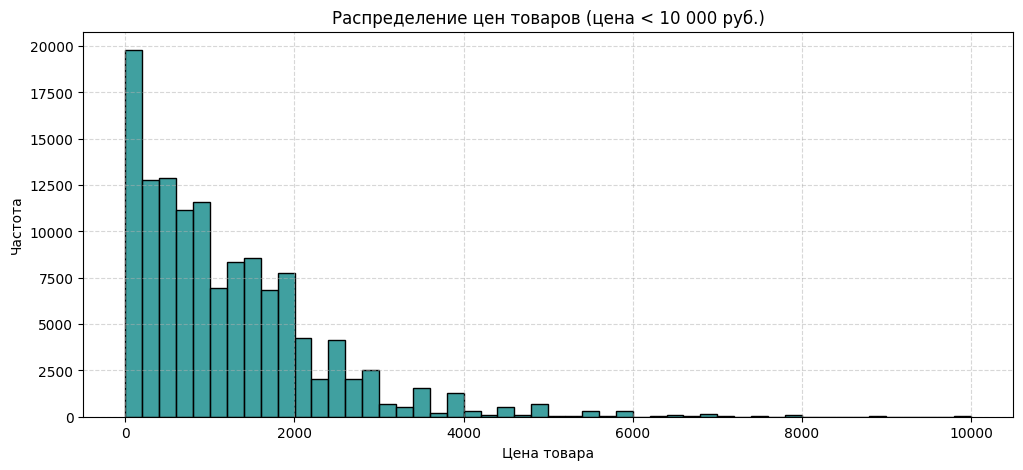

In [ ]:
plt.figure(figsize=(12, 5))
sns.histplot(data=df_purchases[df_purchases['price'] < 10000], x='price', bins=50, color='teal')
plt.title('Распределение цен товаров (цена < 10 000 руб.)')
plt.xlabel('Цена товара')
plt.ylabel('Частота')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Выводы:
- Распределение скошено вправо: чем дороже товар, тем реже его покупают
- Основной ценовой сегмент от 0 до 2000  

### Динамика покупок и выручки по месяцам

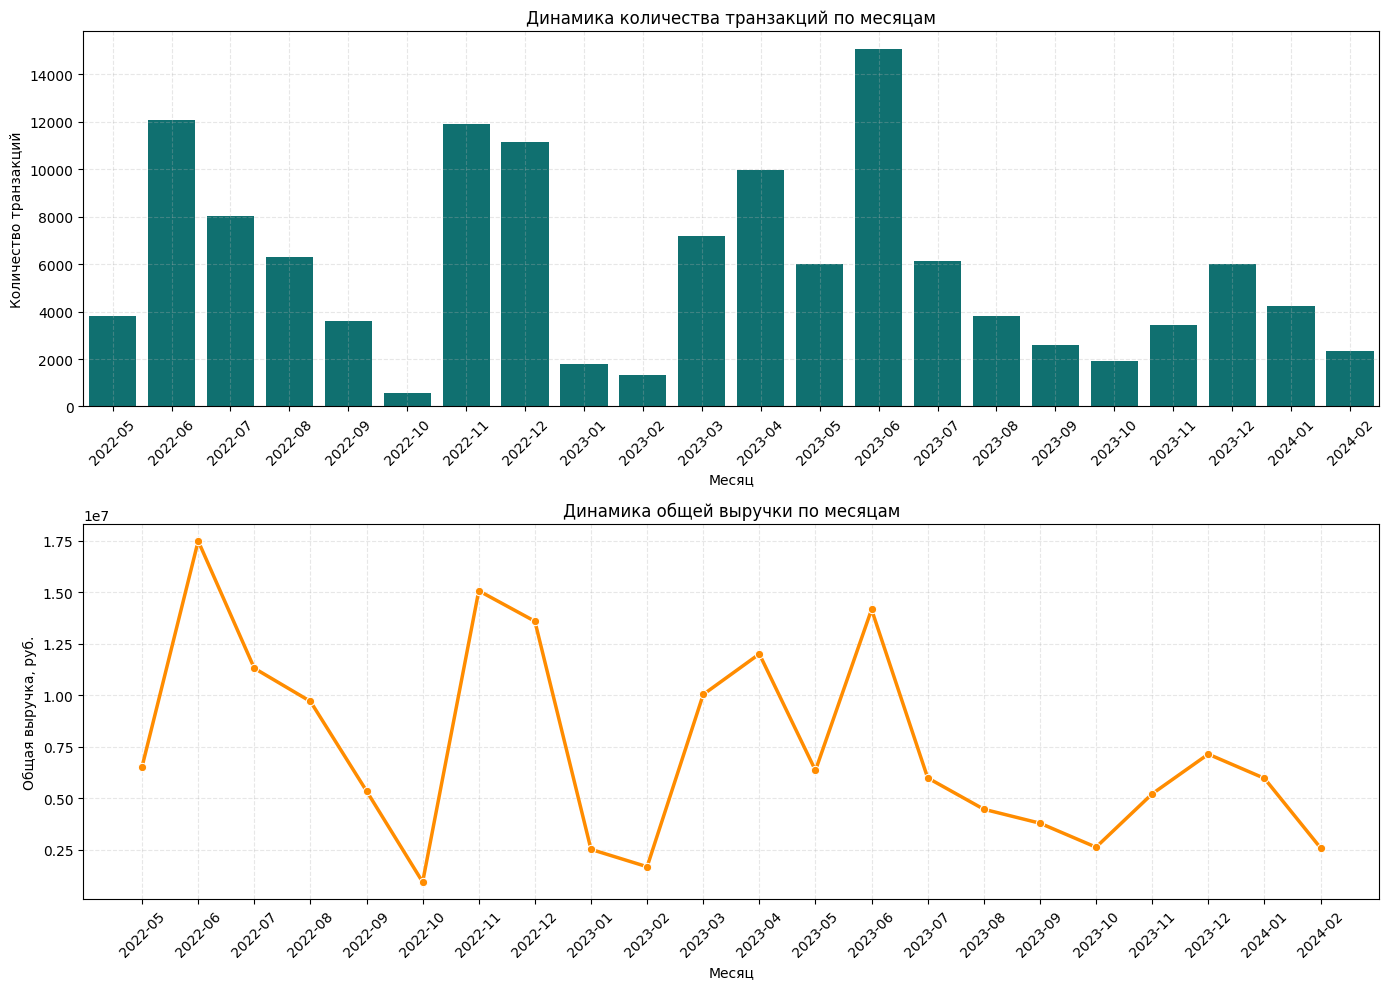

In [ ]:
# Создадим новый признак total_revenue (общая выручка)
df_purchases['total_revenue'] = df_purchases['quantity'] * df_purchases['price']

# Выделим месяц и год из существующей даты покупки
df_purchases['year_month'] = pd.to_datetime(df_purchases['date']).dt.to_period('M').astype(str)

# Группируем по месяцам
purchases_by_month = df_purchases.groupby('year_month').agg(
    orders_count=('client_id', 'count'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

# Строим графики динамики
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Количество покупок
sns.barplot(
    data=purchases_by_month,
    x='year_month',
    y='orders_count',
    ax=axes[0],
    color='teal'
    )

axes[0].set_title('Динамика количества транзакций по месяцам')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Количество транзакций')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.3)

# Выручка
sns.lineplot(
    data=purchases_by_month,
    x='year_month',
    y='total_revenue',
    ax=axes[1],
    marker='o',
    color='darkorange',
    linewidth=2.5
    )

axes[1].set_title('Динамика общей выручки по месяцам')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Общая выручка, руб.')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Выводы:
- Синхронность объема заказов и общей выручки: кривая выручки практически полностью повторяет профиль столбиковой диаграммы транзакций
- Пик продаж приходится на ноябрь–декабрь 2022 и июнь 2023
- Сезонный спад: глубокие просадки наблюдаются в январе–феврале обоих лет

### Исследование категорий товаров

Проверим признак `category_ids` на наличие пустых категорий:

In [ ]:
(df_purchases[df_purchases['category_ids'].str.len() < 5])['category_ids'].value_counts()

,count
category_ids,
[],2738


Среди покупок есть те, которым не присвоена категория

In [ ]:
top_categories = df_purchases['category_ids'].value_counts().head(15).reset_index()

top_categories.columns = ['ID Категории', 'Количество покупок']

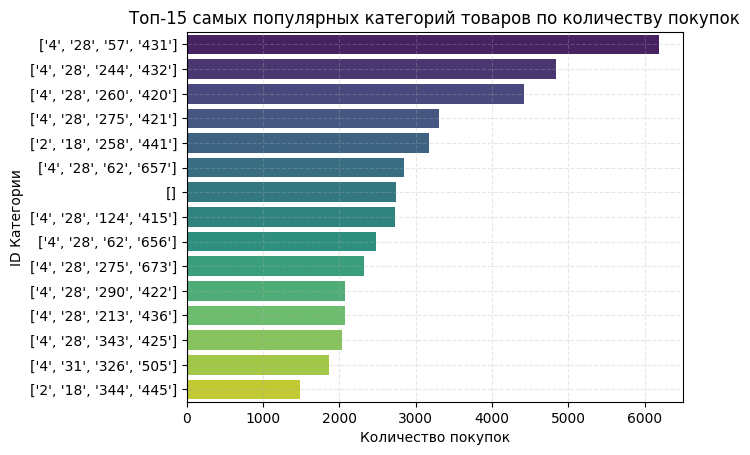

In [ ]:
sns.barplot(
    data=top_categories,
    x='Количество покупок',
    y='ID Категории',
    hue='ID Категории',
    palette='viridis'
    )

plt.title('Топ-15 самых популярных категорий товаров по количеству покупок')
plt.xlabel('Количество покупок')
plt.ylabel('ID Категории')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

Выводы:
- Абсолютным лидером с большим отрывом является цепочка категорий ['4', '28', '57', '431']
- Подавляющее большинство категорий в топе начинаются с пути верхнего уровня ['4', '28', ...]
- Наличие пустых категорий [] в топе

## Группировка данных

Сгруппируем данные по client_id.

Введем следующие метрики:
- total_spent: общая сумма трат клиента.
- total_items: суммарное количество купленных товаров.
- mean_receipt: средняя стоимость одной позиции (чек).
- max_receipt: максимальная стоимость позиции.
- days_since_last_purchase: количество дней, прошедших с момента последней покупки клиента.

---



In [ ]:
# Определим глобальную максимальную дату в покупках для подсчета давности
global_max_purchase_date = df_purchases['date'].max()

# Группируем покупки по клиентам
purchases_agg = df_purchases.groupby('client_id').agg(
    total_spent=('total_revenue', 'sum'),
    total_items=('quantity', 'sum'),
    mean_receipt=('total_revenue', 'mean'),
    max_receipt=('total_revenue', 'max'),
    last_purchase_date=('date', 'max')
).reset_index()

# Рассчитаем количество дней с момента последней покупки
purchases_agg['days_since_last_purchase'] = (global_max_purchase_date - purchases_agg['last_purchase_date']).dt.days
purchases_agg.drop(columns=['last_purchase_date'], inplace=True)

display(purchases_agg.head())

,client_id,total_spent,total_items,mean_receipt,max_receipt,days_since_last_purchase
0,1515915625468060902,4795.0,5,959.000000,1999.0,630
1,1515915625468061003,14135.0,6,2355.833333,3499.0,408
2,1515915625468061099,299.0,1,299.000000,299.0,640
3,1515915625468061100,1049.0,1,1049.000000,1049.0,6
4,1515915625468061170,14102.0,8,1762.750000,2699.0,244


# df_target

In [ ]:
df_target.head()

,client_id,target
0,1515915625468060902,0
1,1515915625468061003,1
2,1515915625468061099,0
3,1515915625468061100,0
4,1515915625468061170,0


In [ ]:
df_target.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49849 entries, 0 to 49848
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   client_id  49849 non-null  int64
 1   target     49849 non-null  int64
dtypes: int64(2)
memory usage: 779.0 KB


Проверим данные на наличие дубликотов в `client_id`:

In [ ]:
sum_dupl = df_target['client_id'].duplicated().sum()

print(f'Количество дубликатов в client_id:', sum_dupl)

Количество дубликатов в client_id: 0


Отобразим распределение целевого признака:

,Факт покупки,"Процент, %"
0,Нет,98.07
1,Да,1.93


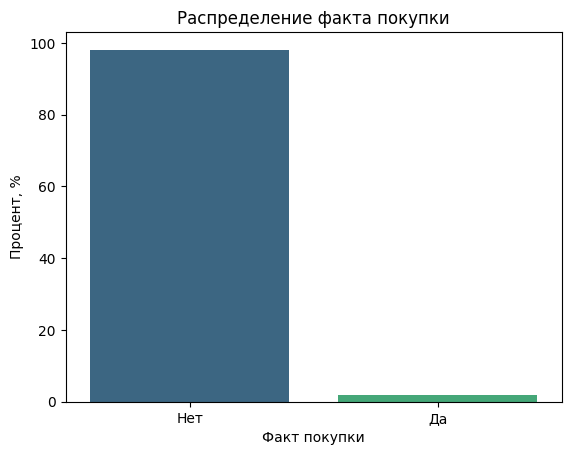

In [ ]:
# Считаем доли покупок и переводим их в проценты
df_pct = df_target['target'].value_counts(normalize=True).reset_index()
df_pct['target'] = df_pct['target'].map({0: 'Нет', 1: 'Да'})
df_pct['proportion'] = round(df_pct['proportion'] * 100, 2)

# Переименовываем колонку
df_pct.columns = ['Факт покупки', 'Процент, %']

# Выводим табличные данные
display(df_pct)

# Строим график
sns.barplot(
    data=df_pct,
    x='Факт покупки',
    y='Процент, %',
    hue='Факт покупки',
    palette='viridis',
    legend=False
)

plt.title('Распределение факта покупки');

Выводы:
- Дисбаланс классов: подавляющее большинство клиентов не совершают покупку в целевой период (98 %)

# df_final

Объеденим таблицы df_messages, df_purchases, df_target по общему ключу - client_id

In [ ]:
# Объединяем целевую переменную с агрегированными данными о покупках
df_final = df_target.merge(purchases_agg, on='client_id', how='left')

# Присоединяем агрегированные маркетинговые признаки без дублирования
df_final = df_final.merge(client_messages_final, on='client_id', how='left')

## Первичный обзор данных

In [ ]:
df_final.head()

,client_id,target,total_spent,total_items,mean_receipt,max_receipt,days_since_last_purchase,email_send,email_open,email_click,email_open_rate,email_ctor,mobile_push_send,mobile_push_open,mobile_push_click,push_open_rate,push_ctor,negative_signals,days_since_last_message
0,1515915625468060902,0,4795.0,5,959.000000,1999.0,630,43.0,17.0,8.0,0.3953,0.4706,0.0,0.0,0.0,0.0,0.0,0.0,5.0
1,1515915625468061003,1,14135.0,6,2355.833333,3499.0,408,49.0,1.0,0.0,0.0204,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1515915625468061099,0,299.0,1,299.000000,299.0,640,52.0,9.0,4.0,0.1731,0.4444,44.0,22.0,0.0,0.5,0.0,1.0,0.0
3,1515915625468061100,0,1049.0,1,1049.000000,1049.0,6,0.0,0.0,0.0,0.0000,0.0000,68.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1515915625468061170,0,14102.0,8,1762.750000,2699.0,244,38.0,12.0,9.0,0.3158,0.7500,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49849 entries, 0 to 49848
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   client_id                 49849 non-null  int64  
 1   target                    49849 non-null  int64  
 2   total_spent               49849 non-null  float64
 3   total_items               49849 non-null  int64  
 4   mean_receipt              49849 non-null  float64
 5   max_receipt               49849 non-null  float64
 6   days_since_last_purchase  49849 non-null  int64  
 7   email_send                36084 non-null  float64
 8   email_open                36084 non-null  float64
 9   email_click               36084 non-null  float64
 10  email_open_rate           36084 non-null  float64
 11  email_ctor                36084 non-null  float64
 12  mobile_push_send          36084 non-null  float64
 13  mobile_push_open          36084 non-null  float64
 14  mobile

В таблице final_dataset обнаружены пропущенные значений во всех маркетинговых метриках.

Причина пропуска: В целевой таблице есть клиенты, которые совершали покупки, но маркетинговые кампании они не учавствовали

Заполним все маркетинговые признаки 0, так как никакой активности не было. Давность последнего сообщения для таких «молчаливых» клиентов можно заполнить специальным значением-заглушкой (например, 999), указывающим на отсутствие контактов.

In [ ]:
# Список колонок с маркетинговыми показателями для заполнения нулями
fill_zero_cols = [
    'email_send', 'email_open', 'email_click', 'email_open_rate', 'email_ctor',
    'mobile_push_send', 'mobile_push_open', 'mobile_push_click',
    'push_open_rate', 'push_ctor', 'negative_signals'
]

# Заполняем пропуски в метриках нулями
df_final[fill_zero_cols] = df_final[fill_zero_cols].fillna(0)

# Заполняем пропуск в давности сообщения заглушкой 999
df_final['days_since_last_message'] = df_final['days_since_last_message'].fillna(999)

# Проверяем, остались ли пропуски
print("Осталось пропущенных значений:", df_final.isna().sum().sum())

Осталось пропущенных значений: 0


## Исследовательский анализ данных

### Распределение признаков по классам

Распределение давности покупки по классам:

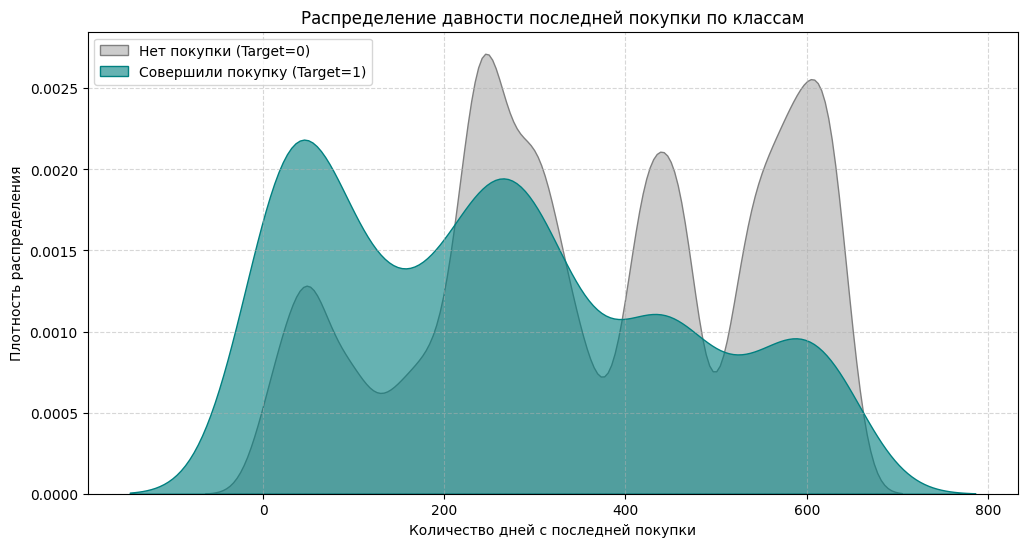

In [ ]:
plt.figure(figsize=(12, 6))

# Строим графики распределения для обоих классов
sns.kdeplot(
    data=df_final[df_final['target'] == 0],
    x='days_since_last_purchase',
    label='Нет покупки (Target=0)',
    fill=True,
    alpha=0.4,
    color='gray'
    )

sns.kdeplot(
    data=df_final[df_final['target'] == 1],
    x='days_since_last_purchase',
    label='Совершили покупку (Target=1)',
    fill=True,
    alpha=0.6,
    color='teal'
    )

plt.title('Распределение давности последней покупки по классам')
plt.xlabel('Количество дней с последней покупки')
plt.ylabel('Плотность распределения')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Поведение клиентов, которые совершат повторную покупку (Target=1), отличается по давности от тех, кто покупку не совершил (Target=0):

- У совершивших покупку (Target=1) первый и самый высокий пик плотности приходится на диапазон до 50–70 дней с последней покупки. Начиная со 100 дней и далее, кривая для Target=1 демонстрирует выраженный нисходящий тренд. Чем «свежее» клиент, тем выше его склонность к повторной покупке.

- Распределение обоих классов имеет выраженную структуру. Это свидетельствует о циклическом характере бизнеса и сезонности

Распределение характеристик по классам

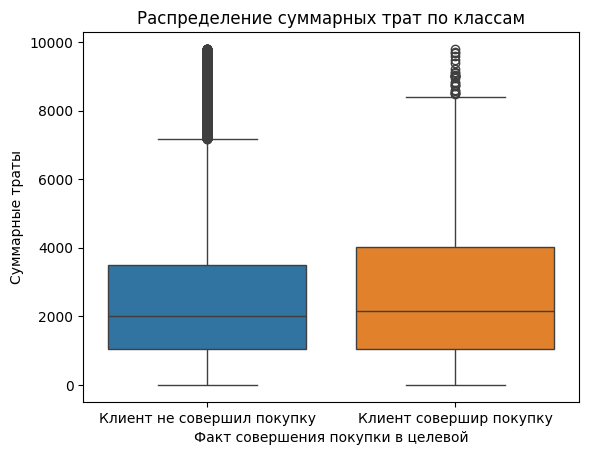

In [ ]:
quantile_num = df_final['total_spent'].quantile(0.95)

plot_data = df_final[df_final['total_spent'] < quantile_num]

sns.boxplot(
    data=plot_data,
    x='target',
    y='total_spent',
    hue='target',
    legend=False
)

plt.xlabel('Факт совершения покупки в целевой')
plt.ylabel('Суммарные траты')
plt.title('Распределение суммарных трат по классам')
plt.xticks([0, 1], ['Клиент не совершил покупку', 'Клиент совершир покупку']);

- Медианы у обеих групп находятся практически на одном уровне (около 2000 р.)
- Сам по себе исторический факт того, сколько клиент суммарно потратил ранее, не является определяющим фактором совершения новой покупки в целевой период

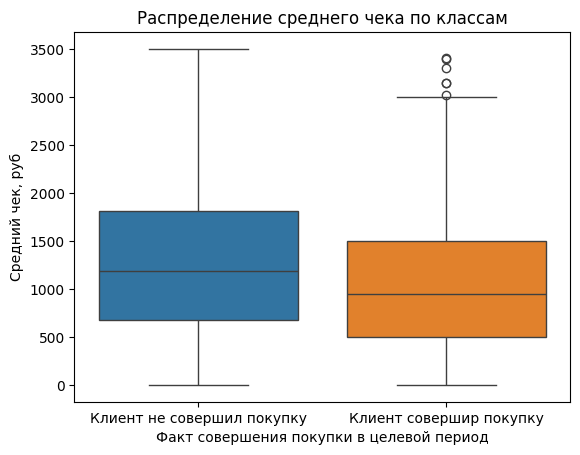

In [ ]:
quantile_num = df_final['mean_receipt'].quantile(0.95)

plot_data = df_final[df_final['mean_receipt'] < quantile_num]

sns.boxplot(
    data=plot_data,
    x='target',
    y='mean_receipt',
    hue='target',
    legend=False
)

plt.xlabel('Факт совершения покупки в целевой период')
plt.ylabel('Средний чек, руб')
plt.title('Распределение среднего чека по классам')
plt.xticks([0, 1], ['Клиент не совершил покупку', 'Клиент совершир покупку']);

Медиана среднего чека у клиентов, совершивших покупку в целевой период, составляет около 1 000 руб, у некупивших клиентов медиана выше — около ~1 200 руб.

### Корреляционный анализ

Числовые признаки имеют выбросы или скошенные распределения. Для оценки корреляции будем использвать коэффициент Спирмена

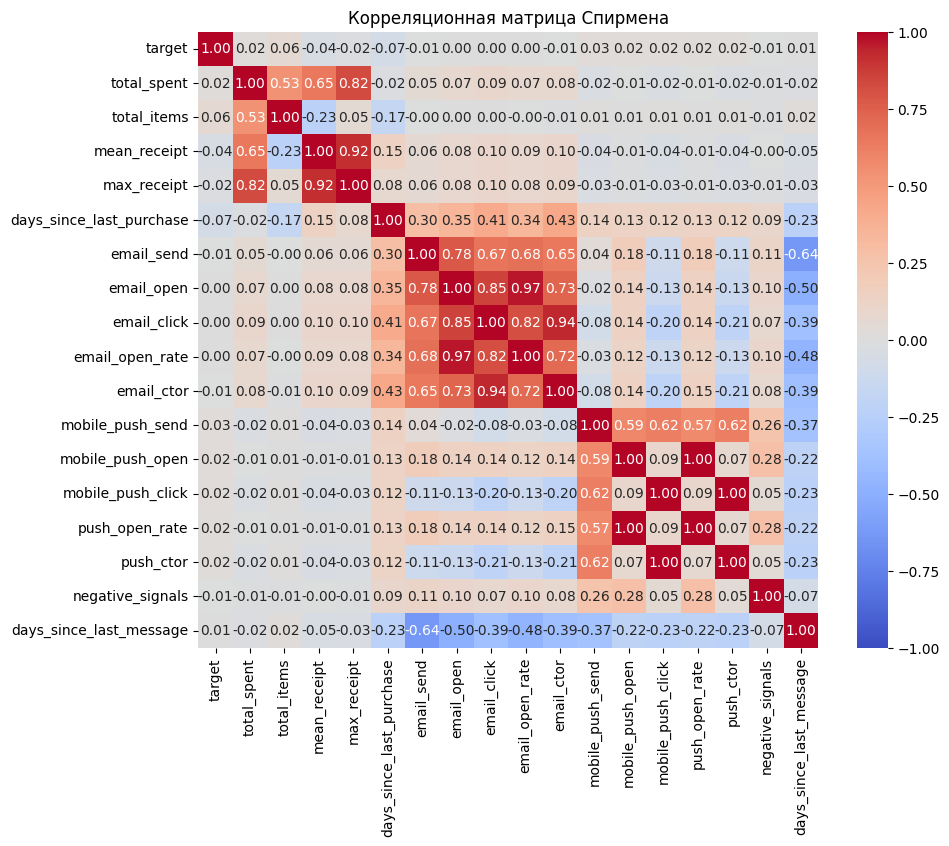

In [ ]:
clean_features = [col for col in df_final.columns if col != 'client_id']

# Корреляция Спирмена
corr_clean = df_final[clean_features].corr(method='spearman')

# Тепловая карта
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_clean,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
    )
plt.title('Корреляционная матрица Спирмена')
plt.show()

Между признаками обнаружена мультиколлинеарность:
- mean_receipt и max_receipt - 0.92
- mobile_push_open и push_open_rate - 0.97
- mobile_push_click - push_ctor - 0.98

Избавимся от одного из признаков в каждой паре

Низкие абсолютные значения связи с таргетом объясняются сильным дисбалансом классов (~2% покупателей) и нелинейной природой поведения

# Моделирование

## Подготовка данных

In [ ]:
# Разделение на признаки (X) и таргет (y)
X = df_final.drop(columns=['client_id', 'target', 'max_receipt', 'mobile_push_open', 'mobile_push_click'])
y = df_final['target']

# Стратифицированное разбиение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Обучение модели

Для оценки качества модели будем использовать метрику ROC-AUC

Построим наивную модель:

In [ ]:
# Инициализация базового классификатора
dummy_clf = DummyClassifier(strategy='prior', random_state=42)

# Обучение
dummy_clf.fit(X_train, y_train)

# Предсказание вероятностей и классов
y_dummy_prob = dummy_clf.predict_proba(X_test)[:, 1]

# Оценка метрик бейзлайна
dummy_roc_auc = roc_auc_score(y_test, y_dummy_prob)

print(f"Dummy ROC-AUC: {dummy_roc_auc:.4f}")

Dummy ROC-AUC: 0.5000


Для задачи классификации будем использовать модель LightGBM

In [ ]:
# Словарь гиперпараметров
param_distributions = {
    'n_estimators': [100, 200, 450],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [15, 31, 63],
    'max_depth': [3, 5, 8]
}

# Кросс-валидация со стратификацией
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE)


# Инициализация модели LGBMClassifier
base_lgb = LGBMClassifier(
    objective='binary',
    boosting_type='gbdt',
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

# Подбор гиперпараметров с кросс-валидацией
random_search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='roc_auc',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=LGBMClassifier(class_weight='balanced', n_jobs=-1,
                                            objective='binary', random_state=42,
                                            verbose=-1),
                   n_jobs=1,
                   param_distributions={'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 5, 8],
                                        'n_estimators': [100, 200, 450],
                                        'num_leaves': [15, 31, 63]},
                   random_state=42, scoring='roc_auc', verbose=1)

In [ ]:
best_model = random_search.best_estimator_
print(f"Лучшая оценка на кросс-валидации (ROC-AUC): {random_search.best_score_:.4f}")
print("Оптимальные гиперпараметры:", random_search.best_params_)

Лучшая оценка на кросс-валидации (ROC-AUC): 0.6891
Оптимальные гиперпараметры: {'num_leaves': 31, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}


## Тестирование модели

In [ ]:
y_test_proba = best_model.predict_proba(X_test)[:, 1]
y_test_pred = best_model.predict(X_test)

test_roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"\nИтоговый ROC-AUC на тестовой выборке: {test_roc_auc:.4f}")


Итоговый ROC-AUC на тестовой выборке: 0.7322


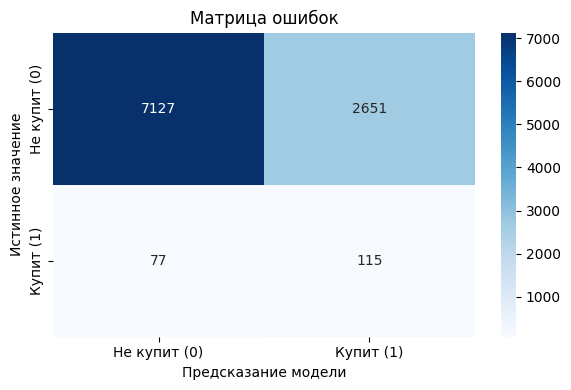

In [ ]:
# Отрисовка матрицы ошибок
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_test_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не купит (0)', 'Купит (1)'],
    yticklabels=['Не купит (0)', 'Купит (1)']
)
plt.title('Матрица ошибок')
plt.xlabel('Предсказание модели')
plt.ylabel('Истинное значение')
plt.tight_layout()
plt.show()

In [ ]:
# Полный сводный отчет по обоим классам
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9893    0.7289    0.8394      9778
           1     0.0416    0.5990    0.0778       192

    accuracy                         0.7264      9970
   macro avg     0.5154    0.6639    0.4586      9970
weighted avg     0.9711    0.7264    0.8247      9970



- Алгоритм успешно находит ~60% всех потенциальных покупателей

## Анализ важности признаков

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


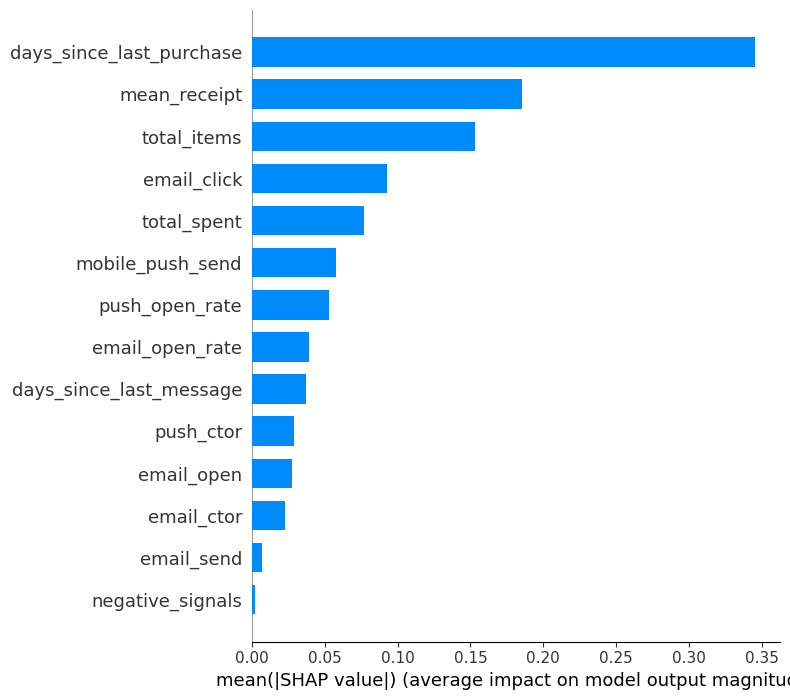

In [ ]:
# Берем случайную выборку из обучающих данных
X_sample = X_train.sample(1000, random_state=42)

# Создаем Explainer для древесной модели LightGBM
explainer = shap.TreeExplainer(best_model)

# Считаем SHAP-значения для нашей выборки
shap_values = explainer.shap_values(X_sample)

# Строим график
shap.summary_plot(shap_values, X_sample, plot_type="bar")

# ВЫВОДЫ

1. **Краткое резюме**

Разработана ML-модель на базе алгоритма LightGBM для предсказания вероятности совершения клиентом повторной покупки в ближайшее время. Модель успешно находит около 60% потенциальных покупателей в условиях экстремального дисбаланса классов.

2. **Бизнес инсайты**

- **Оптимизация каналов связи:** Доказана превосходящая коммерческая эффективность Email-рассылок. Несмотря на то, что мобильные Push-уведомления открываются чаще (35.45% против 27.29% у email), Email в 3 раза эффективнее конвертирует сообщения в итоговые продажи (1.86% против 0.71%).

- **Тайминг коммуникаций:** Выявлен выраженный «офисный» паттерн активности аудитории. Основное взаимодействие с рассылками происходит в будние дни с 07:00 до 16:00, с абсолютным максимумом открытий в 14:00.

- **Важность "свежести" клиента:** Анализ показал, что вероятность повторной покупки наиболее высока в первые 50–70 дней после предыдущего заказа, после чего начинает резко снижаться.

3. **Технические результаты**
- **Качество и подготовка данных:** Построен надежный пайплайн трансформации данных. Устранены скрытые дубликаты (более 74 тыс. строк логов), устранены проблемы мультиколлинеарности признаков (удалены дублирующие метрики). Сырые логи событий успешно агрегированы в плоскую витрину на уровне уникального client_id.

- **Моделирование:** Для работы с дисбалансом классов (целевой класс — 1.93%) применена стратифицированная кросс-валидация и взвешивание классов class_weight='balanced'. Лучшие результаты показала модель LightGBM.

- **Метрики качества:** На отложенной тестовой выборке достигнут ROC-AUC 0.7322. Метрика Recall для целевого класса составила 0.5990.

- **Интерпретируемость (SHAP):** С помощью TreeExplainer выявлено, что наибольший вклад в прогноз модели вносят давность последней покупки (days_since_last_purchase), средний чек (mean_receipt) и суммарное количество купленных товаров (total_items).

4. **Ограничения и зоны роста**

Текущая модель сфокусирована на полноте (Recall), что ведет к снижению точности (Precision). Анализ Precision-Recall кривой и подбор оптимального порога predict_proba позволит бизнесу балансировать между затратами на отправку рассылок и упущенной выгодой.
